In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import numpy as np


In [2]:
df=pd.read_excel("/content/compound.xlsx")
df

,compound name,Antineoplastic,Anti-Inflammatory,Anti-Tumor,OPP
0,Gitogenin,1,0,1,1
1,D-Galactose,1,1,0,1
2,Tigogenin,1,0,0,1
3,Hecogenin,1,1,1,1
4,D-Glucose,1,0,1,1
...,...,...,...,...,...
1291,Rapanone,1,0,0,0
1292,Sym-homospermidine,1,0,0,0
1293,"1,3-Diaminopropane",1,0,0,0
1294,2-Nonenal,1,0,0,0


In [3]:
print(df.head())  # Check if the column name has changed
print(df.columns)


  compound name  Antineoplastic  Anti-Inflammatory  Anti-Tumor  OPP
0     Gitogenin               1                  0           1    1
1   D-Galactose               1                  1           0    1
2     Tigogenin               1                  0           0    1
3     Hecogenin               1                  1           1    1
4     D-Glucose               1                  0           1    1
Index(['compound name', 'Antineoplastic', 'Anti-Inflammatory', 'Anti-Tumor',
       'OPP'],
      dtype='object')


In [4]:
# Feature selection
feature_columns = ["Antineoplastic", "Anti-Inflammatory", "Anti-Tumor", "OPP"]
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df[feature_columns])


In [5]:
# Handle NaN or infinite values if present
if np.any(np.isnan(df[feature_columns])) or np.any(np.isinf(df[feature_columns])):
    df = df.dropna(subset=feature_columns)

n_clusters = 5
kmeans = KMeans(n_clusters=n_clusters, random_state=0, n_init=10)
df['Cluster'] = kmeans.fit_predict(df[feature_columns])

print("Number of compounds in each cluster:")
print(df['Cluster'].value_counts())

Number of compounds in each cluster:
Cluster
0    853
1    161
3    135
4     77
2     70
Name: count, dtype: int64


In [6]:
# Calculate cluster means
cluster_means = df.groupby('Cluster')[feature_columns].mean()
print("Mean Values for Each Cluster:")
print(cluster_means)

Mean Values for Each Cluster:
         Antineoplastic  Anti-Inflammatory  Anti-Tumor       OPP
Cluster                                                         
0                   1.0                0.0    0.023447  0.000000
1                   1.0                1.0    1.000000  0.875776
2                   1.0                0.0    0.300000  1.000000
3                   1.0                1.0    0.000000  1.000000
4                   1.0                1.0    0.000000  0.000000


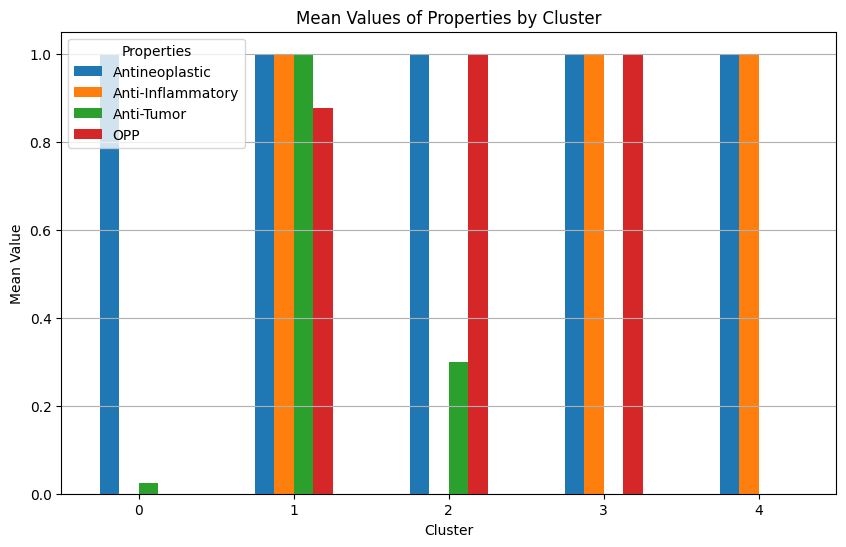

In [12]:
# Plot mean values of properties per cluster
ax = cluster_means.plot(kind='bar', figsize=(10, 6))
plt.title('Mean Values of Properties by Cluster')
plt.ylabel('Mean Value')
plt.xlabel('Cluster')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.legend(title='Properties')

plt.savefig("cluster_mean_plot.png", dpi=300, bbox_inches='tight')  # Save image
plt.show()

In [13]:
# Save cluster distribution
cluster_distribution = df['Cluster'].value_counts().reset_index()
cluster_distribution.columns = ['Cluster', 'Number of Compounds']
cluster_distribution.to_excel('Cluster_Distribution.xlsx', index=False)

In [14]:
# Save compound clustering results
grouped = df.groupby('Cluster')['compound name'].apply(list).reset_index()
grouped.columns = ['Cluster', 'Compounds']
compounds_expanded = grouped['Compounds'].apply(pd.Series)
compounds_expanded.columns = [f'Compound {i+1}' for i in range(compounds_expanded.shape[1])]
final_output = pd.concat([grouped[['Cluster']], compounds_expanded], axis=1)
final_output.to_excel('Compounds_by_Cluster.xlsx', index=False)
print(final_output)


   Cluster                                         Compound 1  \
0        0  2-methyl-N-[1-(3-phenylprop-2-enoyl)pyrrolidin...   
1        1                                          Hecogenin   
2        2                                          Gitogenin   
3        3                                        D-Galactose   
4        4                                  Benzyl salicylate   

                                          Compound 2          Compound 3  \
0  (8S,9S,10R,13R,14S)-17-[(2R,5R)-5-ethyl-6-meth...        Triglochinin   
1                                         Kaempferol           Quercetin   
2                                          Tigogenin           D-Glucose   
3                                   Roxburghiadiol A       Syringic acid   
4                                 (+)-delta-Selinene  (+)-alpha-Cadinene   

                        Compound 4         Compound 5  \
0                      Cholesterol  Methyl propionate   
1                     Ursolic acid    

In [15]:
# Compute Silhouette Score
silhouette_avg = silhouette_score(scaled_features, df['Cluster'])
print(f'Silhouette Score: {silhouette_avg}')

silhouette_df = pd.DataFrame({'Silhouette Score': [silhouette_avg]})
silhouette_df.to_excel('Clustering_Silhouette_Score.xlsx', index=False)

Silhouette Score: 0.9171977989307095


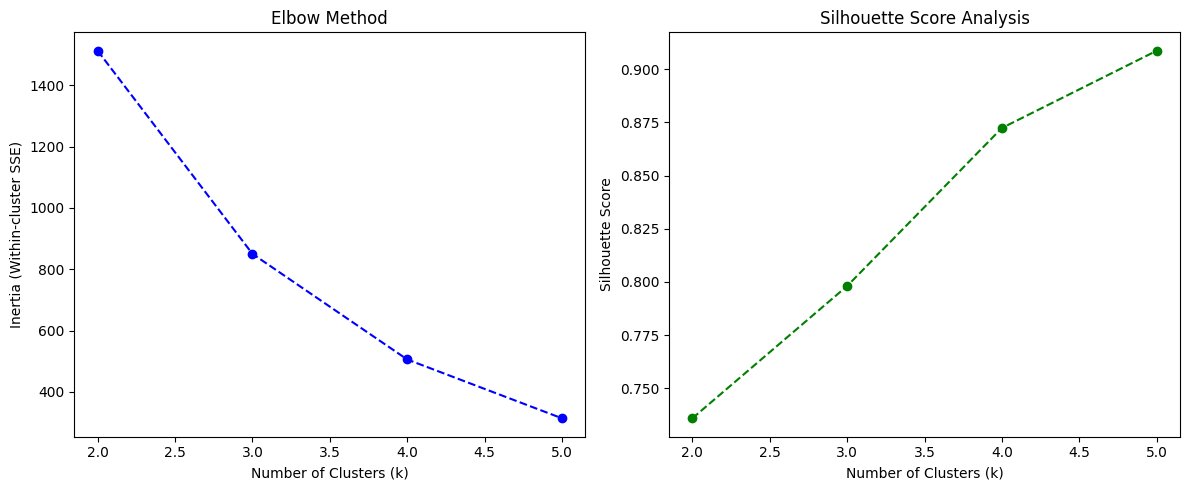

In [16]:
inertia = []
silhouette_scores = []
k_values = range(2, 6)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(scaled_features)
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(scaled_features, kmeans.labels_))

plt.figure(figsize=(12, 5))

# Elbow Method Plot
plt.subplot(1, 2, 1)
plt.plot(k_values, inertia, marker='o', linestyle='--', color='b')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia (Within-cluster SSE)")
plt.title("Elbow Method")

# Silhouette Score Plot
plt.subplot(1, 2, 2)
plt.plot(k_values, silhouette_scores, marker='o', linestyle='--', color='g')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score Analysis")

plt.tight_layout()
plt.savefig("cluster_silhouette.png", dpi=300, bbox_inches='tight')  # Save image
plt.show()



In [17]:
# Calculate a composite ranking score for each cluster
cluster_means['Ranking Score'] = cluster_means.sum(axis=1)
# Rank clusters based on the composite score in descending order
cluster_ranking = cluster_means[['Ranking Score']].sort_values(by='Ranking Score', ascending=False)
cluster_ranking['Rank'] = range(1, len(cluster_ranking) + 1)
# Save the ranking to an Excel file
cluster_ranking.to_excel('Cluster_Ranking.xlsx', index_label='Cluster')
# Display the ranking
print("Cluster Ranking based on composite score:")
print(cluster_ranking)

Cluster Ranking based on composite score:
         Ranking Score  Rank
Cluster                     
1             3.875776     1
3             3.000000     2
2             2.300000     3
4             2.000000     4
0             1.023447     5
